# Project Milestone Two: Modeling and Feature Engineering

### Overview

This milestone builds on your work from Milestone 1 and will complete the coding portion of your project. You will:

1. Pick 3 modeling algorithms from those we have studied.
2. Evaluate baseline models using default settings.
3. Engineer new features and re-evaluate models.
4. Use feature selection techniques and re-evaluate.
5. Fine-tune for optimal performance.
6. Select your best model and report on your results.

You must do all work in this notebook and upload to your team leader's account in Gradescope. There is no
Individual Assessment for this Milestone.


In [ ]:
# ===================================
# Useful Imports: Add more as needed
# ===================================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars
import seaborn as sns

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

# Progress Tracking

from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



### Prelude: Load your Preprocessed Dataset from Milestone 1

In Milestone 1, you handled missing values, encoded categorical features, and explored your data. Before you begin this milestone, you’ll need to load that cleaned dataset and prepare it for modeling. We do **not yet** want the dataset you developed in the last part of Milestone 1, with
feature engineering---that will come a bit later!

Here’s what to do:

1. Return to your Milestone 1 notebook and rerun your code through Part 3, where your dataset was fully cleaned (assume it’s called `df_cleaned`).

2. **Save** the cleaned dataset to a file by running:

>   df_cleaned.to_csv("zillow_cleaned.csv", index=False)

3. Switch to this notebook and **load** the saved data:

>   df = pd.read_csv("zillow_cleaned.csv")

4. Create a **train/test split** using `train_test_split`.  
   
6. **Standardize** the features (but not the target!) using **only the training data.** This ensures consistency across models without introducing data leakage from the test set:

>   scaler = StandardScaler()   
>   X_train_scaled = scaler.fit_transform(X_train)    
  
**Notes:**

- You will have to redo the scaling step if you introduce new features (which have to be scaled as well).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Add as many cells as you need
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DX603 Group 48/zillow_cleaned.csv')
X, y = df.drop(columns='taxvaluedollarcnt'), df['taxvaluedollarcnt']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

### Part 1: Picking Three Models and Establishing Baselines [6 pts]

Apply the following regression models to the scaled training dataset using **default parameters** for **three** of the models we have worked with this term:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regression
- Bagging
- Random Forest
- Gradient Boosting Trees

For each of the three models:
- Use **repeated cross-validation** (e.g., 5 folds, 5 repeats).
- Report the **mean and standard deviation of CV MAE Score**.


In [ ]:
# Add as many cells as you need
def training(model, n_splits=5, n_repeats=5, params=None):
  """Train model with X-fold cross-validation and return mean and standard deviation of CV MAE Score."""
  kfold = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats)
  score = cross_val_score(model, X_train_scaled, y_train, scoring='neg_mean_absolute_error', cv=kfold, params=params)
  return score, f'{type(model).__name__} CV MAE Score: {score.mean()}. CV MAE Standard Deviation: {score.std()}'

In [ ]:
linreg, linregreport = training(LinearRegression())

In [ ]:
dtree, dtreereport = training(DecisionTreeRegressor())

In [ ]:
rf, rfreport = training(RandomForestRegressor())

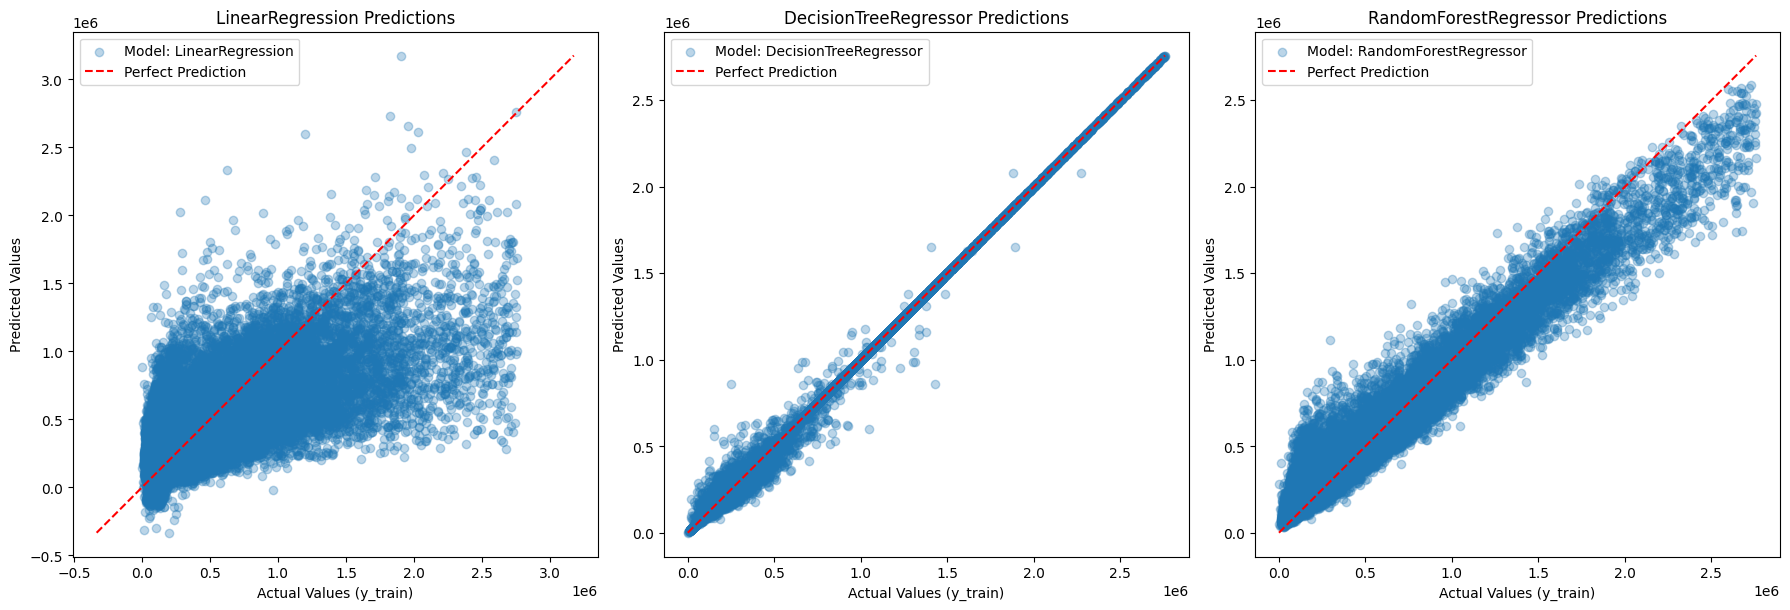

In [ ]:
models = [LinearRegression(), DecisionTreeRegressor(), RandomForestRegressor()]
plt.figure(figsize=(18, 6)) # Increased figure size for better readability
for i in range(len(models)):
    model = models[i]
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_train_scaled)

    ax = plt.subplot(1, 3, i + 1)
    ax.scatter(y_train, predictions, alpha=0.3, label=f"Model: {type(model).__name__}")

    # Plot the perfect prediction line (y=x)
    min_val = min(y_train.min(), predictions.min())
    max_val = max(y_train.max(), predictions.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label="Perfect Prediction")

    ax.set_xlabel("Actual Values (y_train)")
    ax.set_ylabel("Predicted Values")
    ax.set_title(f"{type(model).__name__} Predictions")
    ax.legend(loc="best")
    ax.set_aspect('equal', adjustable='box') # To ensure the y=x line is truly diagonal

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

In [ ]:
display(linregreport, dtreereport, rfreport)

'LinearRegression() CV MAE Score: -194176.2847349201. CV MAE Standard Deviation: 1208.0175844731584'

'DecisionTreeRegressor() CV MAE Score: -217197.87149644576. CV MAE Standard Deviation: 2156.473447184371'

'RandomForestRegressor() CV MAE Score: -165840.43688103845. CV MAE Standard Deviation: 1175.9965655747824'

### Part 1: Discussion [3 pts]

In a paragraph or well-organized set of bullet points, briefly compare and discuss:

  - Which model performed best overall?
  - Which was most stable (lowest std)?
  - Any signs of overfitting or underfitting?

> Best overall model in performance: Random Forest Regressor, which had the best mean CV MAE score and lowest standard deviation, making it the most stable as well.

> Based on the prediction charts, Decision Tree Regressor shows signs of overfitting for values > 1, while Linear Regression shows signs of underfitting as it predicted very poorly.

### Part 2: Feature Engineering [6 pts]

Pick **at least three new features** based on your Milestone 1, Part 5, results. You may pick new ones or
use the same ones you chose for Milestone 1.

Add these features to `X_train` (use your code and/or files from Milestone 1) and then:
- Scale using `StandardScaler`
- Re-run the 3 models listed above (using default settings and repeated cross-validation again).
- Report the **mean and standard deviation of CV MAE Scores**.  


In [ ]:
# Add as many cells as you need
def get_feature_ratio(df, feature1, feature2):
  return df[feature1] / df[feature2]

def get_feature_sum(df, feature1, feature2):
  return df[feature1] + df[feature2]

def polar_coords(df):
  x = df['latitude']
  y = df['longitude']
  r = np.sqrt(x**2 + y**2)
  p = np.atan2(y, x)
  return r, p

def single_pt_haversine(lat, lng):
    """
    'Single-point' Haversine: Calculates the great circle distance
    between a point on Earth and the (0, 0) lat-long coordinate
    """
    r = 6371 # Earth's radius (km). Have r = 3956 if you want miles

    # 'Single-point' Haversine formula
    a = np.sin(lat/2)**2 + np.cos(lat) * np.sin(lng/2)**2
    d = 2 * r * np.asin(np.sqrt(a))
    return d

X_train['space_room_ratio'] = get_feature_ratio(X_train, 'finishedsquarefeet12', 'calculatedbathnbr')
X_train['room_unit_sum'] = get_feature_sum(X_train, 'roomcnt', 'unitcnt')
X_train['polar_lat'], X_train['polar_long'] = polar_coords(X_train)
X_train['haversine'] = single_pt_haversine(X_train['latitude'], X_train['longitude'])
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [ ]:
linregFE, linregFEreport = training(LinearRegression())

In [ ]:
dtreeFE, dtreeFEreport = training(DecisionTreeRegressor())

In [ ]:
rfFE, rfFEreport = training(RandomForestRegressor())

In [ ]:
display(linregFEreport, dtreeFEreport, rfFEreport)

'LinearRegression CV MAE Score: -194127.8796661839. CV MAE Standard Deviation: 1207.9978495553703'

'DecisionTreeRegressor CV MAE Score: -218396.7414828625. CV MAE Standard Deviation: 2041.5851282645265'

'RandomForestRegressor CV MAE Score: -165485.38373640628. CV MAE Standard Deviation: 1657.445630591461'

### Part 2: Discussion [3 pts]

Reflect on the impact of your new features:

- Did any models show notable improvement in performance?

- Which new features seemed to help — and in which models?

- Do you have any hypotheses about why a particular feature helped (or didn’t)?




> The models did not show notable improvement in performance. None of the new features seemed to help. The Linear Regression and Decision Tree had slightly lower mean CV MAE scores and standard deviations, while the Random Forest was higher for both. Hypothesis: the polar coordinates and haverstine formula did not help because there isn't a strong enough correlation between latitude, longitude, and taxvaluedollarcnt. Another hypothesis: space to room ratio did not help because prospective buyers are more concerned with a combination of other factors, such as neighborhood and appliances.

### Part 3: Feature Selection [6 pts]

Using the full set of features (original + engineered):
- Apply **feature selection** methods to investigate whether you can improve performance.
  - You may use forward selection, backward selection, or feature importance from tree-based models.
- For each model, identify the **best-performing subset of features**.
- Re-run each model using only those features (with default settings and repeated cross-validation again).
- Report the **mean and standard deviation of CV MAE Scores**.  


In [ ]:
# Add as many cells as you need
models = [LinearRegression(), DecisionTreeRegressor(), RandomForestRegressor()]
featureset = []
for i in range(len(models)):
  for_selection = SequentialFeatureSelector(models[i], direction = "forward", cv = 3)
  for_selection.fit(X_train, y_train)
  features_selected = X_train.columns[for_selection.get_support()]
  print(f"13 best-performing subset of features for {type(models[i]).__name__}: ", features_selected)
  featureset.append(features_selected)


13 best-performing subset of features for LinearRegression:  Index(['bathroomcnt', 'bedroomcnt', 'buildingqualitytypeid',
       'calculatedfinishedsquarefeet', 'finishedsquarefeet12', 'longitude',
       'lotsizesquarefeet', 'rawcensustractandblock', 'regionidcounty',
       'roomcnt', 'space_room_ratio', 'polar_lat', 'polar_long'],
      dtype='object')
13 best-performing subset of features for DecisionTreeRegressor:  Index(['bathroomcnt', 'calculatedbathnbr', 'fips', 'fullbathcnt',
       'heatingorsystemtypeid', 'propertylandusetypeid', 'regionidcity',
       'regionidcounty', 'regionidzip', 'roomcnt', 'unitcnt', 'assessmentyear',
       'room_unit_sum'],
      dtype='object')
13 best-performing subset of features for RandomForestRegressor:  Index(['bathroomcnt', 'calculatedbathnbr', 'calculatedfinishedsquarefeet',
       'fips', 'fullbathcnt', 'latitude', 'propertylandusetypeid',
       'regionidcity', 'regionidcounty', 'regionidzip', 'unitcnt', 'yearbuilt',
       'assessmentyear

In [ ]:
trainings = []
for i in range(len(models)):
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train[featureset[i]])
  trainings.append(training(models[i]))
for result in trainings:
  print(result[1])

LinearRegression CV MAE Score: -193974.53909931358. CV MAE Standard Deviation: 1867.3455634484508
DecisionTreeRegressor CV MAE Score: -186357.66664758432. CV MAE Standard Deviation: 1905.2456517411533
RandomForestRegressor CV MAE Score: -170120.70596045686. CV MAE Standard Deviation: 1438.3963877011392


### Part 3: Discussion [3 pts]

Analyze the effect of feature selection on your models:

- Did performance improve for any models after reducing the number of features?

- Which features were consistently retained across models?

- Were any of your newly engineered features selected as important?


In [ ]:
pd.DataFrame(np.ravel(featureset)).value_counts()

,count
0,
bathroomcnt,3
regionidcounty,3
assessmentyear,2
fips,2
calculatedbathnbr,2
fullbathcnt,2
regionidcity,2
propertylandusetypeid,2
calculatedfinishedsquarefeet,2


> After reducing the number of features, performance significantly improved for all three models in mean CV MAE score, particularly for the decision tree model. The linear regression model improved in CV MAE standard deviation, but the tree models both performed slightly worse in that metric.

> Across models, bathroom count, region id county were retained in all three models. The tree models shared 8 out of the 10 features that were retained by only 2 models. The linear model shared feature retention of calculated finished square feet with the random forest model and room count with the decision tree model.

> Space room ratio and the polar coordinates were selected as important in the linear model. Room unit sum was selected as important in the decision tree model.

### Part 4: Fine-Tuning Your Three Models [6 pts]

In this final phase of Milestone 2, you’ll select and refine your **three most promising models and their corresponding data pipelines** based on everything you've done so far, and pick a winner!

1. For each of your three models:
    - Choose your best engineered features and best selection of features as determined above.
   - Perform hyperparameter tuning using `sweep_parameters`, `GridSearchCV`, `RandomizedSearchCV`, `Optuna`, etc. as you have practiced in previous homeworks.
3. Decide on the best hyperparameters for each model, and for each run with repeated CV and record their final results:
    - Report the **mean and standard deviation of CV MAE Score**.  

In [ ]:
# Add as many cells as you need

featureset_manual = [
    ['bathroomcnt', 'bedroomcnt', 'buildingqualitytypeid',
       'calculatedfinishedsquarefeet', 'finishedsquarefeet12', 'longitude',
       'lotsizesquarefeet', 'rawcensustractandblock', 'regionidcounty',
       'roomcnt', 'space_room_ratio', 'polar_lat', 'polar_long'],
    ['bathroomcnt', 'calculatedbathnbr', 'fips', 'fullbathcnt',
       'heatingorsystemtypeid', 'propertylandusetypeid', 'regionidcity',
       'regionidcounty', 'regionidzip', 'roomcnt', 'unitcnt', 'assessmentyear',
       'room_unit_sum'],
    ['bathroomcnt', 'calculatedbathnbr', 'calculatedfinishedsquarefeet',
       'fips', 'fullbathcnt', 'latitude', 'propertylandusetypeid',
       'regionidcity', 'regionidcounty', 'regionidzip', 'unitcnt', 'yearbuilt',
       'assessmentyear']
]

X_train['space_room_ratio'] = get_feature_ratio(X_train, 'finishedsquarefeet12', 'calculatedbathnbr')
X_train['room_unit_sum'] = get_feature_sum(X_train, 'roomcnt', 'unitcnt')
X_train['polar_lat'], X_train['polar_long'] = polar_coords(X_train)
X_train['haversine'] = single_pt_haversine(X_train['latitude'], X_train['longitude'])

def tune_and_evaluate(model, param_grid, X_subset, y, n_splits=5, n_repeats=5, search='grid', n_iter=20, label="Model"):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_subset)

    kfold = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)

    if search == 'grid':
        searcher = GridSearchCV(model, param_grid, scoring='neg_mean_absolute_error',
                                cv=3, n_jobs=-1, verbose=1)
    else:
        searcher = RandomizedSearchCV(model, param_grid, scoring='neg_mean_absolute_error',
                                      cv=3, n_iter=n_iter, n_jobs=-1,
                                      random_state=random_state, verbose=1)

    searcher.fit(X_scaled, y)
    best_params = searcher.best_params_
    print(f"\n{label} — Best Params: {best_params}")

    best_model = searcher.best_estimator_
    scores = cross_val_score(best_model, X_scaled, y, scoring='neg_mean_absolute_error', cv=kfold, n_jobs=-1)
    mae_scores = -scores
    print(f"CV MAE Mean: {mae_scores.mean():,.2f} // Std: {mae_scores.std():,.2f}")
    return best_params, mae_scores


In [ ]:
ridge_params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

best_params_lr, scores_lr = tune_and_evaluate(
    Ridge(),
    ridge_params,
    X_train[featureset_manual[0]],
    y_train,
    search='grid',
    label="Ridge (Linear Regression)"
)

Fitting 3 folds for each of 7 candidates, totalling 21 fits

Ridge (Linear Regression) — Best Params: {'alpha': 1000}
CV MAE Mean: 194,032.01 // Std: 1,191.90


In [ ]:
dt_params = {
    'max_depth':        [3, 5, 10, 15, 20, None],
    'min_samples_split':[2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features':     ['sqrt', 'log2', None]
}

best_params_dt, scores_dt = tune_and_evaluate(
    DecisionTreeRegressor(random_state=random_state),
    dt_params,
    X_train[featureset_manual[1]],
    y_train,
    search='grid',
    label="Decision Tree Regressor"
)

Fitting 3 folds for each of 288 candidates, totalling 864 fits


In [ ]:
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5]
}

best_params_rf, scores_rf = tune_and_evaluate(
    RandomForestRegressor(random_state=random_state),
    rf_params,
    X_train[featureset_manual[2]],
    y_train,
    search='random',
    n_iter=15,
    label="Random Forest Regressor"
)

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Random Forest Regressor — Best Params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20}
CV MAE Mean: 167,362.58 // Std: 1,137.74


In [ ]:
summary = pd.DataFrame({
    'Model':    ['Ridge (Linear Reg)', 'Decision Tree', 'Random Forest'],
    'Best Params': [best_params_lr, best_params_dt, best_params_rf],
    'CV MAE Mean': [-scores_lr.mean(), -scores_dt.mean(), -scores_rf.mean()],
    'CV MAE Std':  [scores_lr.std(),   scores_dt.std(),   scores_rf.std()]
})

summary['CV MAE Mean'] = [scores_lr.mean(), scores_dt.mean(), scores_rf.mean()]
display(summary)

,Model,Best Params,CV MAE Mean,CV MAE Std
0,Ridge (Linear Reg),{'alpha': 1000},194032.005512,1191.896240
1,Decision Tree,"{'max_depth': 20, 'max_features': None, 'min_s...",181214.624746,1574.730591
2,Random Forest,"{'n_estimators': 200, 'min_samples_split': 2, ...",167362.576622,1137.739937


### Part 4: Discussion [3 pts]

Reflect on your tuning process and final results:

- What was your tuning strategy for each model? Why did you choose those hyperparameters?
- Did you find that certain types of preprocessing or feature engineering worked better with specific models?


### Tuning Strategies

**Linear Regression**

For tuning the hyperparameters for linear regression we first had to pivot specifically to ridge regression so as to introduce a hyperparameter, *alpha*, referring to the regularization strength. Using GridSearchCV we could quickly sweep a large range.

Feature engineering as well as scaling was especially relevant with this ridge regression model so that each feature was considered fairly despite magnitude.

**Decision Tree Regressor**

Our decision tree model already had hyperparameters we could tune such as max_depth, min_samples_split, min_samples_leaf, and max_features. We could once again use GridSearchCV to test these parameters.

Feature Engineering is relevant in our decision tree model, by providing *shortcuts* for the tree through bonus features such as `space_room_ratio` so the tree does not have to derive that relationship itself.

**Random Forest**

Random Forest has a much larger search space than the other models requiring compromises to be made in the tuning of hyperparameters. The paramters tuned were n_estimators, max_depth, min_samples_split, min_samples_leaf, and max_features. For efficiency reasons due to limited compute, we reduced the number of iterations and made educated guesses on parameters prior to running.

Random forest receives similar benefits from feature engineering as our decision tree model. Specifically for random forest, however, having our bonus features increases the total amount of information that can be utilized by our decision trees.

### Part 5: Final Model and Design Reassessment [6 pts]

In this part, you will finalize your best-performing model.  You’ll also consolidate and present the key code used to run your model on the preprocessed dataset.
**Requirements:**

- Decide one your final model among the three contestants.

- Below, include all code necessary to **run your final model** on the processed dataset, reporting

    - Mean and standard deviation of CV MAE Score.
    
    - Test score on held-out test set.




In [ ]:
# Add as many cells as you need

best_params_final = best_params_rf
scores_final = scores_rf

best_rf_features = [
    'bathroomcnt', 'calculatedbathnbr', 'calculatedfinishedsquarefeet',
    'fips', 'fullbathcnt', 'latitude', 'propertylandusetypeid',
    'regionidcity', 'regionidcounty', 'regionidzip', 'unitcnt', 'yearbuilt',
    'assessmentyear'
]

X_test_5 = X_test.copy()

X_test_5['space_room_ratio'] = get_feature_ratio(X_test_5, 'finishedsquarefeet12', 'calculatedbathnbr')
X_test_5['room_unit_sum'] = get_feature_sum(X_test_5, 'roomcnt', 'unitcnt')
X_test_5['polar_lat'], X_test_5['polar_long'] = polar_coords(X_test_5)
X_test_5['haversine'] = single_pt_haversine(X_test_5['latitude'], X_test_5['longitude'])

X_test_5 = X_test_5.replace([np.inf, -np.inf], np.nan)
X_test_5 = X_test_5.fillna(X_train.median(numeric_only=True))

X_train_final = X_train[best_rf_features]
X_test_final = X_test_5[best_rf_features]

final_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features=0.5,
    max_depth=20,
    random_state=random_state,
    n_jobs=-1
)

final_model.fit(X_train_final, y_train)
test_preds = final_model.predict(X_test_final)

test_mae = np.mean(np.abs(y_test - test_preds))

part5_summary = pd.DataFrame({
    'Model': ['Random Forest'],
    'Best Params': [best_params_final],
    'CV MAE Mean': [scores_final.mean()],
    'CV MAE Std': [scores_final.std()],
    'Held-out Test MAE': [test_mae]
})

display(part5_summary)


,Model,Best Params,CV MAE Mean,CV MAE Std,Held-out Test MAE
0,Random Forest,"{'n_estimators': 200, 'min_samples_split': 2, ...",167362.576622,1137.739937,167804.966467


### Part 5: Discussion [8 pts]

In this final step, your goal is to synthesize your entire modeling process and assess how your earlier decisions influenced the outcome. Please address the following:

1. Model Selection:
- Clearly state which model you selected as your final model and why.

- What metrics or observations led you to this decision?

- Were there trade-offs (e.g., interpretability vs. performance) that influenced your choice?

2. Revisiting an Early Decision

- Identify one specific preprocessing or feature engineering decision from Milestone 1 (e.g., how you handled missing values, how you scaled or encoded a variable, or whether you created interaction or polynomial terms).

- Explain the rationale for that decision at the time: What were you hoping it would achieve?

- Now that you've seen the full modeling pipeline and final results, reflect on whether this step helped or hindered performance. Did you keep it, modify it, or remove it?

- Justify your final decision with evidence—such as validation scores, visualizations, or model diagnostics.

3. Lessons Learned

- What insights did you gain about your dataset or your modeling process through this end-to-end workflow?

- If you had more time or data, what would you explore next?

The final model selected was Random Forest Regressor because it had the best overall performance, with a CV MAE mean of 167,362.58, a CV MAE standard deviation of 1,137.74, and a held-out test MAE of 167,804.97. These results showed that it was both the most accurate and the most stable of the three models. Although Ridge Regression was easier to interpret, Random Forest was better at capturing the more complex relationships in the Zillow housing data. It was also more resistant to overfitting, as ensemble methods reduce variance by aggregating results while maintaining low bias. The less linear a relationship is, the more bias a linear model will have when predicting it. Compared to the single Decision Tree, which showed signs of overfitting due to high variance, the Random Forest model reduced this variance by averaging across many trees, leading to better generalization on unseen data.

One earlier decision I revisited was feature engineering, where I created variables like space_room_ratio, room_unit_sum, and location-based features. These additions did not improve performance very much on their own; they may require more domain knowledge for efficacy, such as basing the locations on distance to city centers. The best improvement for only adding the features was Random Forest Regressor's Mean CV MAE going from -165840.44 to -165485.38.

The final results suggest that feature selection and hyperparameter tuning helped more than the new features themselves. Overall, this process showed that housing data has nonlinear patterns that ensemble tree models handle well, and if I had more time, I would explore stronger neighborhood or location-based features and try additional models like Gradient Boosting.